# Recover a feasible SIP matrix with GFS

A small inverse-design experiment: keep the prescribed FIP and fixed sample size, then ask the existing greedy best-first search to match a feasible target SIP. Exact zero is an empirical outcome, not an assumption.

## 1. Imports and package setup
Run from the repository or this notebook directory. No external population data are needed.

In [16]:
from pathlib import Path
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "graphical_sampling").is_dir())
sys.path.insert(0, str(root))
from package_sampling.utils import inclusion_probabilities
from graphical_sampling import Population, Design, Order
from graphical_sampling.order import Cluster, Zone
from graphical_sampling.criteria import SIPMatchingCriteria
from graphical_sampling.search import GreedyBestFirstSearch

np.set_printoptions(precision=4, suppress=True)
TOL = 2e-6  # Package enumeration stores normalized sample weights as float32.
random.seed(2026)

## 2. Define FIP

Set only `N` and `n`. Positive weights are generated automatically, and your sampling package’s `inclusion_probabilities` converts them to valid FIP summing to `n`, capping certainty units at 1. A fixed seed makes this setup repeatable.

In [17]:
N, n = 120, 10  # Only population size and sample size need editing.
assert isinstance(N, int) and isinstance(n, int) and N >= 2 and 1 <= n <= N
weights = np.random.default_rng(2026).uniform(0.5, 1.5, size=N)
pi = inclusion_probabilities(weights.copy(), n)
assert np.all((pi > 0) & (pi <= 1))
assert np.isclose(pi.sum(), n)
coords = np.column_stack([np.arange(N), np.arange(N) % 3])
population = Population(coords, pi.copy(), variable=np.arange(1, N + 1.0), n=n)
np.testing.assert_allclose(population.inclusions, pi, atol=TOL, rtol=0)
display(pd.DataFrame({"unit": np.arange(N), "pi": pi}))

,unit,pi
0,0,0.056306
1,1,0.094536
2,2,0.080218
3,3,0.072193
4,4,0.070901
...,...,...
115,115,0.044180
116,116,0.048425
117,117,0.087475
118,118,0.060682


## 3. Generate a feasible target SIP matrix

`Order.from_indices` splits each bar into contiguous equal shares. `Design.from_order` constructs systematic intervals; `Design.exchange` splits interval mass and swaps units while preserving FIP and sample cardinality.

The current exchange implementation requires a zone hierarchy. A single global `Cluster`/`Zone` contains all units, so there are no spatial restrictions or frozen boundary units. This is metadata for the existing exchange operation, not a replacement implementation.

In [18]:
num_splits = 4

def fresh_systematic_design():
    order = Order.from_indices(population, num_splits=num_splits)
    order.clusters = [Cluster(label=0, zones=[Zone(
        _indices=np.arange(N), _shares=np.ones(N), sort=list(range(N))
    )])]
    return Design.from_order(population, order)

# Validate the full finite support, rather than only a Monte Carlo sample.
def validate_design(design):
    samples, probs = design.all_samples_and_probs
    assert samples.shape[1] == n
    assert all(len(set(sample)) == n for sample in samples)
    assert np.all(np.isfinite(probs)) and np.all(probs >= 0)
    np.testing.assert_allclose(probs.sum(), 1, atol=TOL, rtol=0)
    np.testing.assert_allclose(design.fip, pi, atol=TOL, rtol=0)
    np.testing.assert_allclose(np.diag(design.sip), pi, atol=TOL, rtol=0)
    np.testing.assert_allclose(design.sip.sum(axis=1), n * pi, atol=TOL, rtol=0)
    return len(probs)

target_design = fresh_systematic_design()
target_design._rng = np.random.default_rng(41)
# Largest-fragment selection avoids a second, independently seeded heap RNG.
for _ in range(3000):
    target_design.exchange(partitions=1, pull_strategy="largest", exchange_coef=0.5)
target_support_size = validate_design(target_design)
target_sip = target_design.sip.copy()
print(f"Feasible target: {target_support_size} support samples, each of size {n}")
# Retain only the target probabilities and the validation evidence.
del target_design

Feasible target: 4059 support samples, each of size 10


## 4. Create a fresh starting GFS design

In [19]:
initial_design = fresh_systematic_design()
validate_design(initial_design)
initial_sip = initial_design.sip.copy()
upper = np.triu_indices(N, k=1)
print("Initial maximum off-diagonal mismatch:",
      np.max(np.abs((initial_sip - target_sip)[upper])))

Initial maximum off-diagonal mismatch: 0.03323888783779694


## 5. Use the SIP-matching criterion

`SIPMatchingCriteria` subclasses the package's existing `Criteria` and implements `evaluate(design)`. It computes
$C=\sqrt{\mathrm{mean}_{k<l}(\Pi_{kl}-\Pi^*_{kl})^2}$.
Only the target matrix enters the objective. Diagonal errors are excluded.

In [20]:
criterion = SIPMatchingCriteria(target_sip)
initial_criterion = criterion(initial_design)
assert initial_criterion >= 0
if initial_criterion <= TOL:
    print("The initial SIP already matches the target within tolerance.")
print(f"Initial criterion: {initial_criterion:.8f}")

Initial criterion: 0.00509134


## 6. Run optimization

Use the existing GBFS exchange neighbors only. No order neighbors are needed. The progress callback records the current working objective and the all-time best from the reservoir after each productive iteration. Iteration gaps can occur when no new candidates are found. Backtracking is disabled for this small baseline experiment by setting its stagnation limit above the iteration budget.

The package creates fresh unseeded RNGs inside `Design.copy`, so search results vary between runs despite the fixed target. This notebook does not modify the optimizer to change its randomness.

Random fragment selection broadens exploration beyond the two largest fragments. Duplicate detection in GBFS now distinguishes designs with the same support but different probability masses.

Search output is configured with `output_mode="objective"` and `objective_name="SIP RMSE"`. Use `output_mode="spatial"` for spread sampling diagnostics (Moran, cluster/zone counts, support size, entropy, and variance), or `"silent"` to suppress search messages. `output_details=True` prints every evaluated candidate. The notebook callback prints separate progress summaries.

In [21]:
max_iterations = 2500
history = [{"iteration": 0, "current_criterion": initial_criterion,
            "best_criterion": initial_criterion}]

def record_progress(search, iteration):
    if iteration % 100 == 0:
        print(f"Iteration {iteration}: SIP RMSE = {search.best_criteria_value:.8f}, "
              f"best SIP RMSE = {search.reservoir_val:.8f}")
    history.append({"iteration": iteration,
                    "current_criterion": search.best_criteria_value,
                    "best_criterion": search.reservoir_val})

search = GreedyBestFirstSearch([initial_design], criterion)
search.run(
    max_iterations=max_iterations, max_open_set_size=100, top_k=1,
    num_new_order_nodes=0, num_new_exchange_nodes=12,
    num_clusters_range=(1, 1), num_zones_range=(1, 1),
    num_changes_range=(1, 2), num_zone_changes=0,
    pull_strategy="random", exchange_coef=0.5,
    num_explore=1, n_jobs=1, stagnation_limit=max_iterations + 1,
    output_mode="objective", objective_name="SIP RMSE",
    output_details=False, progress_callback=record_progress,
)
final_design = search.reservoir_design
final_sip = final_design.sip.copy()
best_criterion = criterion(final_design)
progress = pd.DataFrame(history)
print(f"Last recorded productive iteration: {search.iterations_completed}")

Starting fresh: Initializing Open Set.
--- Parallel GBFS: Batch Size=1, Workers=1 ---
ITR    0 | SIP RMSE 0.00509057 | BEST 0.00509057
ITR    0 | SIP RMSE 0.00507440 | BEST 0.00507440
ITR    0 | SIP RMSE 0.00507295 | BEST 0.00507295
ITR    1 | SIP RMSE 0.00506437 | BEST 0.00506437
ITR    1 | SIP RMSE 0.00505851 | BEST 0.00505851
ITR    1 | SIP RMSE 0.00505814 | BEST 0.00505814
ITR    1 | SIP RMSE 0.00505254 | BEST 0.00505254
ITR    2 | SIP RMSE 0.00505110 | BEST 0.00505110
ITR    2 | SIP RMSE 0.00502041 | BEST 0.00502041
ITR    2 | SIP RMSE 0.00499566 | BEST 0.00499566
ITR    3 | SIP RMSE 0.00498653 | BEST 0.00498653
ITR    3 | SIP RMSE 0.00498596 | BEST 0.00498596
ITR    3 | SIP RMSE 0.00496985 | BEST 0.00496985
ITR    3 | SIP RMSE 0.00496005 | BEST 0.00496005
ITR    4 | SIP RMSE 0.00495173 | BEST 0.00495173
ITR    4 | SIP RMSE 0.00494789 | BEST 0.00494789
ITR    4 | SIP RMSE 0.00491954 | BEST 0.00491954
ITR    5 | SIP RMSE 0.00489165 | BEST 0.00489165
ITR    5 | SIP RMSE 0.00489141 |

KeyboardInterrupt: 

## 7. Convergence

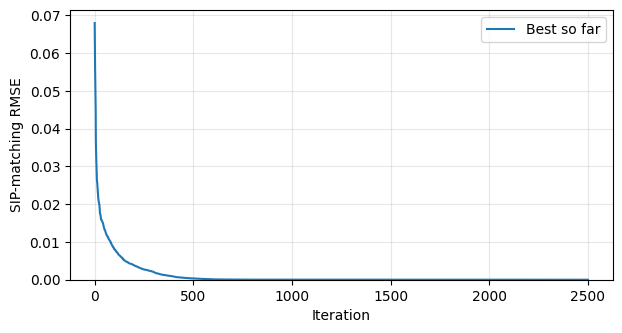

,iteration,current_criterion,best_criterion
0,0,0.067978,0.067978
250,250,0.002732,0.002732
500,500,0.000339,0.000339
750,750,0.000023,0.000023
1000,1000,0.000009,0.000009
1250,1250,0.000006,0.000006
1500,1500,0.000004,0.000004
1750,1750,0.000003,0.000003
2000,2000,0.000002,0.000002
2250,2250,0.000002,0.000002


Initial criterion: 0.06797792
Best criterion: 0.00000177
Improvement: 100.00 %


In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(progress.iteration, progress.best_criterion, label="Best so far")
ax.set(xlabel="Iteration", ylabel="SIP-matching RMSE", ylim=(0, None))
ax.grid(alpha=0.3)
ax.legend()
plt.show()
display(progress.iloc[::max(1, len(progress) // 10)])
print(f"Initial criterion: {initial_criterion:.8f}")
print(f"Best criterion: {best_criterion:.8f}")
improvement = 100 * (1 - best_criterion / initial_criterion) if initial_criterion > 0 else 0.0
print(f"Improvement: {improvement:.2f} %")

## 8. Compare target and recovered SIP matrices

target_sip


,0,1,2,3,4,5,6,7,8,9,10,11
0,0.21346,0.03900,0.02785,0.08659,0.06382,0.04797,0.11223,0.01820,0.02845,0.05445,0.11257,0.04924
1,0.03900,0.35839,0.05293,0.04484,0.11418,0.13202,0.09023,0.13969,0.09876,0.04641,0.20699,0.11012
2,0.02785,0.05293,0.30411,0.03083,0.05092,0.15221,0.10474,0.03208,0.18249,0.04320,0.06493,0.17016
3,0.08659,0.04484,0.03083,0.27369,0.03281,0.05645,0.16269,0.02806,0.03615,0.12502,0.09853,0.11909
4,0.06382,0.11418,0.05092,0.03281,0.26879,0.07030,0.08625,0.08731,0.04469,0.02183,0.16532,0.06895
5,0.04797,0.13202,0.15221,0.05645,0.07030,0.40575,0.12112,0.06283,0.17557,0.06577,0.16124,0.17174
6,0.11223,0.09023,0.10474,0.16269,0.08625,0.12112,0.44178,0.03327,0.13036,0.13649,0.17179,0.17619
7,0.01820,0.13969,0.03208,0.02806,0.08731,0.06283,0.03327,0.21296,0.03775,0.02078,0.13654,0.04238
8,0.02845,0.09876,0.18249,0.03615,0.04469,0.17557,0.13036,0.03775,0.36244,0.06944,0.09369,0.18998
9,0.05445,0.04641,0.04320,0.12502,0.02183,0.06577,0.13649,0.02078,0.06944,0.25099,0.05014,0.11944


initial_sip


,0,1,2,3,4,5,6,7,8,9,10,11
0,0.21346,0.00000,0.00000,0.14966,0.06380,0.00000,0.21346,0.00000,0.00000,0.09237,0.12109,0.00000
1,0.00000,0.35839,0.00000,0.00000,0.20499,0.15341,0.05252,0.21296,0.09291,0.00000,0.34013,0.01826
2,0.00000,0.00000,0.30411,0.00000,0.00000,0.25234,0.05178,0.00000,0.26953,0.03459,0.00000,0.30411
3,0.14966,0.00000,0.00000,0.27369,0.00000,0.00000,0.27369,0.00000,0.00000,0.21640,0.05729,0.12403
4,0.06380,0.20499,0.00000,0.00000,0.26879,0.00000,0.11632,0.15247,0.00000,0.00000,0.26879,0.00000
5,0.00000,0.15341,0.25234,0.00000,0.00000,0.40575,0.00000,0.06049,0.34525,0.00000,0.13514,0.27060
6,0.21346,0.05252,0.05178,0.27369,0.11632,0.00000,0.44178,0.00000,0.01719,0.25099,0.17361,0.17581
7,0.00000,0.21296,0.00000,0.00000,0.15247,0.06049,0.00000,0.21296,0.00000,0.00000,0.21296,0.00000
8,0.00000,0.09291,0.26953,0.00000,0.00000,0.34525,0.01719,0.00000,0.36244,0.00000,0.07465,0.28779
9,0.09237,0.00000,0.03459,0.21640,0.00000,0.00000,0.25099,0.00000,0.00000,0.25099,0.00000,0.15862


final_sip


,0,1,2,3,4,5,6,7,8,9,10,11
0,0.21346,0.03900,0.02784,0.08659,0.06382,0.04798,0.11224,0.01820,0.02844,0.05445,0.11257,0.04924
1,0.03900,0.35839,0.05293,0.04484,0.11418,0.13202,0.09023,0.13969,0.09877,0.04642,0.20699,0.11012
2,0.02784,0.05293,0.30411,0.03083,0.05092,0.15221,0.10474,0.03208,0.18249,0.04319,0.06493,0.17016
3,0.08659,0.04484,0.03083,0.27369,0.03281,0.05645,0.16269,0.02806,0.03615,0.12502,0.09853,0.11909
4,0.06382,0.11418,0.05092,0.03281,0.26879,0.07030,0.08625,0.08731,0.04468,0.02183,0.16531,0.06895
5,0.04798,0.13202,0.15221,0.05645,0.07030,0.40575,0.12112,0.06283,0.17557,0.06577,0.16124,0.17174
6,0.11224,0.09023,0.10474,0.16269,0.08625,0.12112,0.44178,0.03327,0.13037,0.13649,0.17179,0.17619
7,0.01820,0.13969,0.03208,0.02806,0.08731,0.06283,0.03327,0.21296,0.03775,0.02078,0.13654,0.04238
8,0.02844,0.09877,0.18249,0.03615,0.04468,0.17557,0.13037,0.03775,0.36244,0.06944,0.09369,0.18998
9,0.05445,0.04642,0.04319,0.12502,0.02183,0.06577,0.13649,0.02078,0.06944,0.25099,0.05014,0.11944


final_sip - target_sip


,0,1,2,3,4,5,6,7,8,9,10,11
0,-0.0,-0.0,-0.0,0.00000,0.0,0.00000,0.0,-0.0,-0.0,0.0,-0.0,0.0
1,-0.0,-0.0,-0.0,0.00000,0.0,-0.00000,0.0,0.0,0.0,0.0,-0.0,-0.0
2,-0.0,-0.0,-0.0,-0.00000,-0.0,0.00000,0.0,0.0,0.0,-0.0,0.0,0.0
3,0.0,0.0,-0.0,-0.00000,0.0,-0.00001,-0.0,-0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,-0.0,0.00000,-0.0,0.00000,0.0,0.0,-0.0,0.0,-0.0,0.0
5,0.0,-0.0,0.0,-0.00001,0.0,-0.00000,-0.0,-0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,-0.00000,0.0,-0.00000,-0.0,0.0,0.0,-0.0,-0.0,-0.0
7,-0.0,0.0,0.0,-0.00000,0.0,-0.00000,0.0,-0.0,0.0,-0.0,0.0,-0.0
8,-0.0,0.0,0.0,0.00000,-0.0,0.00000,0.0,0.0,-0.0,0.0,-0.0,-0.0
9,0.0,0.0,-0.0,0.00000,0.0,0.00000,-0.0,-0.0,0.0,-0.0,0.0,-0.0


RMSE: 0.00000177
Maximum absolute off-diagonal SIP error: 0.00000511


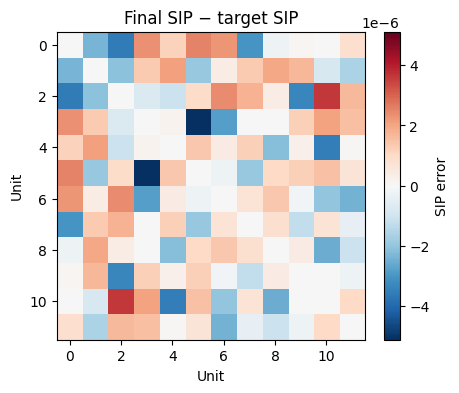

In [ ]:
error = final_sip - target_sip
rmse = np.sqrt(np.mean(error[upper] ** 2))
max_error = np.max(np.abs(error[upper]))
for name, matrix in [("target_sip", target_sip), ("initial_sip", initial_sip),
                     ("final_sip", final_sip), ("final_sip - target_sip", error)]:
    print(name)
    display(pd.DataFrame(matrix).round(5))
print(f"RMSE: {rmse:.8f}")
print(f"Maximum absolute off-diagonal SIP error: {max_error:.8f}")
fig, ax = plt.subplots(figsize=(5, 4))
limit = max(max_error, np.max(np.abs(error)), 1e-12)
im = ax.imshow(error, cmap="RdBu_r", vmin=-limit, vmax=limit)
ax.set(xlabel="Unit", ylabel="Unit", title="Final SIP − target SIP")
fig.colorbar(im, ax=ax, label="SIP error")
plt.show()

## 9. Validate FIP and fixed sample size

In [ ]:
final_support_size = validate_design(final_design)
if initial_criterion > TOL:
    assert best_criterion < initial_criterion, "This run did not improve; inspect the trajectory."
else:
    assert best_criterion <= initial_criterion + TOL
assert np.all(np.diff(progress.best_criterion) <= 1e-12)
np.testing.assert_allclose(rmse, best_criterion, atol=1e-12, rtol=0)
assert target_support_size > 0  # Target support was validated before discarding its design.
print(f"Validation passed: FIP preserved within {TOL:g}; all {final_support_size} "
      f"support samples have exactly {n} distinct units; objective did not worsen.")
print("Target feasibility was established by full support validation before optimization.")
print(f"Residual RMSE {rmse:.8f}; exact recovery is not assumed.")

Validation passed: FIP preserved within 2e-06; all 481 support samples have exactly 4 distinct units; objective did not worsen.
Target feasibility was established by full support validation before optimization.
Residual RMSE 0.00000177; exact recovery is not assumed.


Package changes: `criteria/criteria.py` adds `SIPMatchingCriteria`, `criteria/__init__.py` exports it, and `search/gbfs.py` uses immutable, probability-aware support keys for duplicate detection. Construction, splitting, exchanges, FIP, and SIP implementations are reused. SIP is enumerated over the full support with the package’s float32 probability rounding; it is not estimated by sampling.